# Distance checking, stage by stage

> **In short.**
> * **The setting.** The *distance* of a protocol is the smallest number of faults (a qubit hit by noise, a wrong measurement) that can change its result without any check noticing. For circuits of Clifford gates it can be computed; with non-Clifford gates such as $T$ it is hard.
> * **The idea (L. Yeh's pipeline).** Cut the program into Clifford stretches and the stages with $T$ gates. Give each Clifford stretch its circuit distance. For the $T$ stages, write the reduced diagram as a sum of simple *terms* and check that every term moves an error ($X$, $Y$ or $Z$ on a qubit) to the same place; if it does, errors pass through the $T$ gates as they would through Clifford gates.
> * **The answer on d = 3 cultivation.** The Clifford stretch between injection and double-check has distance 3, but the double-check fails the term check: one term turns an $X$ error into a $Y$ error, the other keeps it an $X$. That agrees with the known fault distance of this circuit with real $T$ gates, 2 (Chan et al.). The check is not proved to decide the distance.
> * **How to read the pictures.** Lines are qubits, time runs left to right, green and red dots are Z- and X-spiders; `π/4` on a green dot is a $T$, `7π/4` a $T^\dagger$. Shades mark the stretches the program is cut into.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

L. Yeh's pipeline for checking the distance of a program with non-Clifford gates, as implemented in `check_distance`:

1. **Cut the stages by gate type** (`split_by_gate_type`): each stage is Clifford, a run of single-qubit non-Clifford gates, or a single-qubit non-Clifford measurement or initialisation (a non-Clifford gate whose qubit is then only rotated and measured, or was just reset). The new program is the same map; only the stage boundaries and the schedule inside them change.
2. **Clifford runs**: every maximal run of Clifford stages gets its circuit distance (`circuit_distance`, between noiseless boundaries; needs `pip install zxqec[distance]`).
3. **Non-Clifford groups**: starting with the first non-Clifford gate stage, the stages from it up to and including the next one are reduced and split into terms (`decompose_terms`, labelling `'fewest links'`). The check is that every term maps each Pauli error to the same Pauli, in every run checked. If it passes, the next group starts at the next non-Clifford gate stage; if not, the group is extended to the next one (or to the end of the program) and checked again.

Non-Clifford measurements and initialisations are post-selections: inside a group they are part of it, outside every group they are listed and not counted. The check is not proved to decide the distance; it agrees with the known fault distances of cultivation (Chan et al., arXiv:2609.17706). For protocols other than cultivation the groups can be given by hand (`groups=`).

In [1]:
from zxqec.qprogram import program_from_stim, split_by_gate_type, check_distance, QProgram
from zxqec.gpf import decompose_terms
from zxqec.spacetime import draw_graph, draw_program
import pyzx as zx
%matplotlib inline
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, T

D3 = open('circuits/cultivation/d3_cultivation.stim').read()
p = program_from_stim(D3)[0]
split = split_by_gate_type(p)
print(split)

11 stages, cut by gate type:
    0  Clifford                     stage 0
    1  Clifford                     stage 1 (part 1 of 2)
    2  non-Clifford measurement     stage 1: T^dag on 13 (measurement)
    3  Clifford                     stage 1 (part 2 of 2)
    4  Clifford                     stage 2
    5  Clifford                     stage 3 (part 1 of 2)
    6  non-Clifford gates           stage 3: T^dag on 0, 3, 6, 8, 9, 11, 14
    7  Clifford                     stage 3 (part 2 of 2)
    8  Clifford                     stage 4 (part 1 of 2)
    9  non-Clifford gates           stage 4: T on 0, 3, 6, 8, 9, 11, 14
   10  Clifford                     stage 4 (part 2 of 2)


## Step 1 on d = 3 cultivation

The file has five stages, cut where a measured qubit is reset. Cut by gate type there are eleven. Stage 2 is the injection's measurement: `T_DAG 13`, then `MX 13`, gathered into one stage (the gates on other qubits in between commute with it). Stages 6 and 9 are the T† layer and the T layer of the double-check on the seven code qubits; the rest is Clifford.

The program cut this way, with the stretches shaded: Clifford stages, the injection's $T^\dagger$ and its X-basis measurement (MX), Clifford stages, the $T^\dagger$ layer, Clifford stages, the $T$ layer, and the last Clifford stage. Each measurement result is a red dot with its name (`c[...]`).

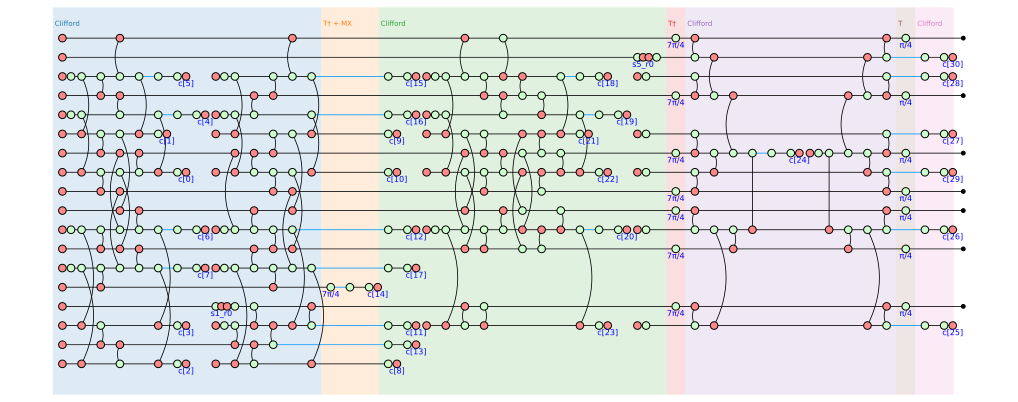

In [2]:
cut = split.program.group_stages([(0, 1, 'Clifford'), (2, 2, 'T† + MX'), (3, 5, 'Clifford'), (6, 6, 'T†'),
                                  (7, 8, 'Clifford'), (9, 9, 'T'), (10, 10, 'Clifford')])
draw_program(split.program, level=cut, show_time=False, labels=False, figsize=(18, 7))

In [3]:
r = check_distance(p)
print(r)

11 stages, cut by gate type:
    0  Clifford                     stage 0
    1  Clifford                     stage 1 (part 1 of 2)
    2  non-Clifford measurement     stage 1: T^dag on 13 (measurement)
    3  Clifford                     stage 1 (part 2 of 2)
    4  Clifford                     stage 2
    5  Clifford                     stage 3 (part 1 of 2)
    6  non-Clifford gates           stage 3: T^dag on 0, 3, 6, 8, 9, 11, 14
    7  Clifford                     stage 3 (part 2 of 2)
    8  Clifford                     stage 4 (part 1 of 2)
    9  non-Clifford gates           stage 4: T on 0, 3, 6, 8, 9, 11, 14
   10  Clifford                     stage 4 (part 2 of 2)
Clifford stages, circuit distance (noiseless boundaries):
  stages 0-1: not computed: NotImplementedError: circuit_distance: one logical qubit after the stages is supported, the code after them has k = 0; give code_out
  stages 3-5: 3 (X -> X: 3, Z -> Z: 3)
  stages 7-8: not computed: NotImplementedError: circuit_d

The group the pipeline checks first, stages 6-9, as a ZX-diagram: the $T^\dagger$ layer (`7π/4`) on the seven code qubits at the left, the Clifford gates of the double-check in the middle, and the $T$ layer (`π/4`) at the right. Its reduced diagram is what `decompose_terms` splits into terms (`DecomposingTerms.ipynb` shows them).

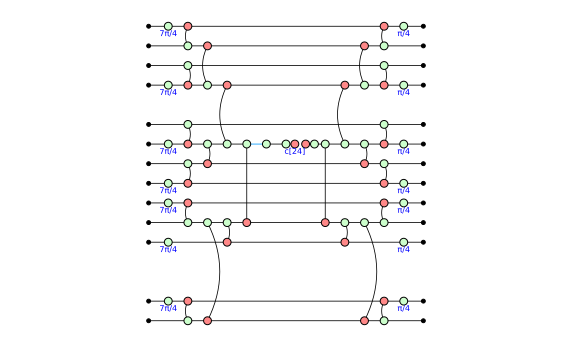

In [4]:
draw_graph(split.program.stages_graph(6, 9, classical=False), show_time=False, figsize=(10, 6))

## Reading the result

* **Clifford runs.** Between the injection and the T† layer (stages 3-5) the circuit distance is 3, the distance of the code. Before the injection (stages 0-1) the code has no logical qubit yet, and between the two T layers (stages 7-8) a code with three logical qubits; `circuit_distance` supports one, so these are reported as not computed, with the reason. Stages 7-8 and 10 lie inside the non-Clifford group anyway.
* **The non-Clifford group.** From the T† layer to the T layer (stages 6-9), the terms are "nothing" and T X T† on every code qubit: single-qubit Clifford gates, but T X T† turns an X error into a Y error while the other term keeps it, so the check fails, in both runs. Extended to the end of the program (stages 6-10) it fails in all 128 runs. So the pipeline does not certify the distance, as it should not: with real T gates the fault distance of d = 3 cultivation is 2, not 3 (Chan et al.).
* **Not counted.** The injection's measurement (stage 2) lies outside the group.

With S in place of T, the version Stim can simulate, every stage is Clifford: there is nothing for step 3 to check. (Its circuit distance is in `CircuitDistance.ipynb`: the program ends with the logical fixed, so `circuit_distance` needs the code to protect, `code_out`.)

In [5]:
swap = {'T': 'S', 'T_DAG': 'S_DAG'}
D3_S = '\n'.join(swap[l.split(' ', 1)[0]] + ' ' + l.split(' ', 1)[1] if l.split(' ', 1)[0] in swap else l
                  for l in D3.splitlines())
r_s = check_distance(program_from_stim(D3_S)[0], distance=False)
print(r_s.split.kinds.count('Clifford'), 'stages, all Clifford; groups pass:', r_s.passes, '(nothing to check)')

5 stages, all Clifford; groups pass: True (nothing to check)


## How a group grows

A small program: T on qubit 0, T on qubit 1, then both undone, with Clifford stages on qubit 2 in between. The first group (T on 0 up to T on 1) turns X errors into errors that are not Pauli, so it is extended to the next non-Clifford gate stage, where the two T gates are undone and the group is the identity on qubits 0 and 1.

In [6]:
def stage(*gates):
    c = Circuit(3)
    for g in gates:
        c.add_gate(g)
    return c

q = QProgram(3)
q.add_circuit(stage(T(0)), name='T on 0')
q.add_circuit(stage(HAD(2)), name='H on 2')
q.add_circuit(stage(T(1)), name='T on 1')
q.add_circuit(stage(HAD(2)), name='H on 2 again')
q.add_circuit(stage(T(0, adjoint=True), T(1, adjoint=True)), name='undo')
print(check_distance(q, distance=False))

5 stages, cut by gate type:
    0  non-Clifford gates           T on 0
    1  Clifford                     H on 2
    2  non-Clifford gates           T on 1
    3  Clifford                     H on 2 again
    4  non-Clifford gates           undo
Clifford stages, circuit distance (noiseless boundaries):
  (none)
non-Clifford groups, every term maps each Pauli error to the same Pauli:
  stages 0-2: False (the only run; 3 inputs, 3 outputs; non-Clifford parts single-qubit: True)
  stages 0-4: True (the only run; 3 inputs, 3 outputs; non-Clifford parts single-qubit: None)
groups pass: True; smallest distance of the Clifford runs: None


The small program, one shade per stage: the $T$ gates (`π/4` on a green dot) on qubits 0 and 1, the Hadamards on qubit 2 (blue segments of its line), and the last stage, whose $T^\dagger$ gates (`7π/4`) undo the first two.

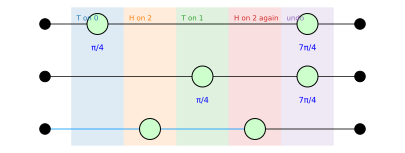

In [7]:
draw_program(q, level=0, show_time=False, figsize=(7, 2.5))

## When the terms are single-qubit

The design expects the terms of a fragment of CNOTs and T gates to be single-qubit gates. They are when the Clifford part around the T gates is undone, as in the double-check above: a T gate conjugated by CNOTs is a phase gadget, and split at its hub it is `I x I` plus `Z x Z`. They are not when it is not undone: after one CNOT and a T, the terms still link the two qubits. (A term can stay connected as a diagram and still be a product; `decompose_terms` decides from its matrix.)

These two cells split the gadget hubs (`split_gadgets=True`) to show the shape of the terms. The check of step 3 never does: split at its hub, a gadget is a sum of Pauli strings, so every term maps Paulis to Paulis whatever the phase (the second example "passes" below, and so would a bare T). Without splitting the hubs, a bare T is one term, T itself, which turns an X error into something that is not a Pauli.

The gadget as a ZX-diagram: a CNOT, a $T$ ($\pi/4$) on qubit 1, and the same CNOT again. Its terms, and those of a CNOT followed by a $T$ that is not undone:

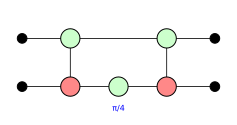

In [8]:
gadget = Circuit(2)
for g in (CNOT(0, 1), T(1), CNOT(0, 1)):
    gadget.add_gate(g)
zx.draw_matplotlib(gadget.to_graph(), figsize=(4, 2))

In [9]:
print(decompose_terms(gadget.to_graph(), split_gadgets=True))
print()
not_undone = Circuit(2)
for g in (CNOT(0, 1), T(1)):
    not_undone.add_gate(g)
print(decompose_terms(not_undone.to_graph(), split_gadgets=True))

labelling 'as reduced': 1 part(s), 1 hidden spider(s)
part 1 (non-Clifford; inputs [0, 1], outputs [0, 1]): hidden gadget hub 1; 2 terms, 2 non-zero
  term 0:
      qubit 0: I (X->X, Y->Y, Z->Z)
      qubit 1: I (X->X, Y->Y, Z->Z)
  term 1:
      qubit 0: Z (X->X, Y->Y, Z->Z)
      qubit 1: Z (X->X, Y->Y, Z->Z)
in every part, every term maps each Pauli error to the same Pauli (up to a sign): True
every term of the non-Clifford parts single-qubit: True (every term single-qubit: True)

labelling 'as reduced': 1 part(s), 1 hidden spider(s)
part 1 (non-Clifford; inputs [0, 1], outputs [0, 1]): hidden gadget hub 1; 2 terms, 2 non-zero
  term 0:
      links qubits 0, 1 (inputs [0, 1], outputs [0, 1])
  term 1:
      links qubits 0, 1 (inputs [0, 1], outputs [0, 1])
in every part, every term maps each Pauli error to the same Pauli (up to a sign): True
every term of the non-Clifford parts single-qubit: False (every term single-qubit: False)


## What this is not

* **Not a proof of distance.** The check on the non-Clifford groups agrees with the known fault distances of cultivation; it is not proved to decide the distance.
* **Not every Clifford run gets a distance.** `circuit_distance` needs one logical qubit after the stages; runs next to the non-Clifford stages can have none or several.
* **Gates keep their order.** Only whole single-qubit measurements and initialisations are gathered; non-Clifford gates are grouped as they come in the gate list.
* **Sampled runs.** A group with more runs than `max_runs` (256) is checked on a seeded sample, and the report says so.
* **Gadget hubs are not split for the check**, for the reason above.